# ATML PA3 · Task 1 — Qwen3-0.6B math fine-tuning (Full FT · L2-SP · LoRA-4/16 · OPLoRA-16)
**CS-6304 / EE-5102 · Danish Rasool (28100233)** · code: https://github.com/danishrasool10/ATML-PA3 (`task_1/`, shared code in `common/`)

### Before running
1. **Settings → Accelerator: GPU T4 ×2**, **Internet: On**.
2. **Add Input** → a dataset containing `first_plot_questions.yaml` (any folder; it is found automatically).
3. Use **Save Version → Save & Run All (Commit)** so the run continues with the browser closed and the outputs are saved.

### What happens
`STAGE = "AUTO"` runs the whole task in one session, in this order, using **both GPUs** (DDP training; evaluations
two at a time, one per GPU): downloads → data (40k MetaMathQA) / probe set / OPLoRA bases / activation cache →
preflight (2-GPU check, FP16 check, worst-case-memory update with ZeRO-1 fallback) → Full FT → evals → L2-SP →
evals → LoRA-4 → LoRA-16 → evals → OPLoRA-16 → eval ‖ diagnostics → qualitative sheet → report tables/figures.

It never runs into Kaggle's 12-hour kill: it stops starting new work when the budget (`BUDGET_HOURS`) runs low,
training pauses with a recovery checkpoint, and the notebook finishes normally so **Kaggle saves the outputs**.
Crashes are retried automatically (training resumes from its latest recovery checkpoint; evaluation OOM halves the
batch size; finished evaluation parts are cached).

### If the status at the end says "paused"
Open the version → **Output** → **New Dataset** (e.g. `pa3-run1`), start a new session with that dataset attached
(plus the questions YAML) and run again. Finished work is detected and skipped; paused training resumes exactly.


In [1]:
# ============================ SETTINGS ============================
import os, time
os.environ.setdefault("PA3_SESSION_START", str(time.time()))   # the session budget starts now
STAGE = "AUTO"              # "AUTO" (everything) | "S0" extended smoke test | "S1" / "S2" / "S3"
BUDGET_HOURS = 11.25        # stop cleanly before Kaggle's 12 h limit (leaves time to save outputs)
REPO_URL = "https://github.com/danishrasool10/ATML-PA3"
REPO_REF = "main"           # branch, tag or commit to run
CODE_DIR = "/kaggle/working/ATML-PA3"
OUTPUT_ROOT = "/kaggle/working/pa3_outputs"
S0_CPU_TESTS = True         # S0 only
USE_ATTACHED_REPO = False   # True = run a repo copy attached as a dataset instead of cloning GitHub

In [2]:
# ============================ GET THE CODE ============================
# Clones GitHub (REPO_REF). Set USE_ATTACHED_REPO=True to run a copy of the repo attached as a dataset instead.
# (Attached earlier-run outputs also contain an old ATML-PA3 copy, so GitHub is the default.)
import glob, shutil, subprocess, time
def _attached_repo():
    for p in sorted(glob.glob("/kaggle/input/**/task_1/src/pa3/orchestrate.py", recursive=True)):
        return os.path.dirname(os.path.dirname(os.path.dirname(os.path.dirname(p))))
    return None
src = _attached_repo() if USE_ATTACHED_REPO else None
if os.path.exists(CODE_DIR):
    shutil.rmtree(CODE_DIR)
if src:
    shutil.copytree(src, CODE_DIR, ignore=shutil.ignore_patterns(".git", "__pycache__"))
    print("using attached repository copy:", src)
else:
    for i in range(4):
        r = subprocess.run(["git", "clone", "--quiet", REPO_URL, CODE_DIR], capture_output=True, text=True)
        if r.returncode == 0:
            break
        print("git clone failed, retrying:", r.stderr[-300:]); time.sleep(15 * (i + 1)); shutil.rmtree(CODE_DIR, ignore_errors=True)
    else:
        raise RuntimeError("could not clone the repository — is Internet enabled?")
    subprocess.run(["git", "-C", CODE_DIR, "checkout", "--quiet", REPO_REF], check=True)
commit = subprocess.run(["git", "-C", CODE_DIR, "rev-parse", "HEAD"], capture_output=True, text=True).stdout.strip()
print("code commit:", commit or "(attached copy, no git metadata)")
os.makedirs(OUTPUT_ROOT, exist_ok=True)
open(f"{OUTPUT_ROOT}/code_commit.txt", "a").write(f"{time.strftime('%Y-%m-%d %H:%M:%S')} {commit or src}\n")

code commit: db89f24aafa0ac0068fce63d4acffd8c904f7025


61

In [3]:
# ============================ DEPENDENCIES ============================
# Pinned versions; Kaggle's PyTorch (CUDA build) is kept as-is.
import sys
sys.path[:0] = [f"{CODE_DIR}/common", f"{CODE_DIR}/task_1/src"]
from pa3common.kaggle import pip_install
import torch
torch_before = torch.__version__
pip_install(["transformers==5.21.0", "peft==0.21.2", "lm_eval[hf]==0.4.13", "pytest", "safetensors", "matplotlib"])
out = subprocess.run([sys.executable, "-c", "import torch, transformers, peft, lm_eval; print(torch.__version__, "
                      "transformers.__version__, peft.__version__)"], capture_output=True, text=True)
print("kernel torch:", torch_before, "| subprocess torch/transformers/peft:", out.stdout.strip(), out.stderr[-400:])
assert out.stdout.split()[0] == torch_before, "pip changed torch — restart the kernel and rerun"
assert tuple(int(x) for x in torch_before.split("+")[0].split(".")[:2]) >= (2, 6), "transformers 5.x needs torch >= 2.6"
gpus = [torch.cuda.get_device_name(i) for i in range(torch.cuda.device_count())]
print("GPUs:", gpus)
if len(gpus) < 2:
    print("!! WARNING: fewer than 2 GPUs visible — select 'GPU T4 x2' in the notebook settings")

ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
gradio 6.26.0 requires pillow<13.0,>=8.0, but you have pillow 13.0.0 which is incompatible.


kernel torch: 2.11.0+cu128 | subprocess torch/transformers/peft: 2.11.0+cu128 5.21.0 0.21.2 
GPUs: ['Tesla T4', 'Tesla T4']


In [4]:
# ============================ RUN ============================
os.chdir(f"{CODE_DIR}/task_1")
from pa3 import orchestrate as O
info = O.setup_env(OUTPUT_ROOT, budget_hours=BUDGET_HOURS)
assert info["questions_yaml"], "first_plot_questions.yaml not found under /kaggle/input — attach it before running"
runner = {"AUTO": O.stage_auto, "S1": O.stage_s1, "S2": O.stage_s2, "S3": O.stage_s3,
          "S0": lambda: O.stage_s0(cpu_tests=S0_CPU_TESTS)}[STAGE]
result = runner()

{
 "output_root": "/kaggle/working/pa3_outputs",
 "scratch": "/kaggle/temp/pa3_scratch",
 "prior_roots": [],
 "questions_yaml": "/kaggle/working/pa3_outputs/first_plot_questions.yaml",
 "gpus": 2,
 "budget": "11.23 h left of session budget"
}

$ /usr/bin/python3 -m pa3.prefetch
  (log: /kaggle/working/pa3_outputs/logs/prefetch.log)


[prefetch] model Qwen/Qwen3-0.6B cached



[prefetch] training data cached
/kaggle/working/ATML-PA3/task_1/src/pa3/prefetch.py:29: DeprecationWarning: get_task_dict is deprecated. Use TaskManager.load() instead.
  td = get_task_dict(["gsm8k_cot", "hellaswag", "boolq", "arc_easy"], TaskManager())





[Task: boolq] metric acc is defined, but aggregation is not. using default aggregation=mean
[Task: boolq] metric acc is defined, but higher_is_better is not. using default higher_is_better=True






[prefetch] lm-eval arc_easy: 2376 eval docs
[prefetch] lm-eval boolq: 3270 eval docs
[prefetch] lm-eval hellaswag: 10042 eval docs
[prefetch] lm-eval gsm8k_cot: 1

{
 "runs": {
  "full_ft": "done",
  "full_ft_l2sp": "done",
  "lora_r4": "done",
  "lora_r16": "done",
  "oplora_r16": "done"
 },
 "evals": {
  "baseline": "done",
  "fullft_u0625": "done",
  "fullft_u1250": "done",
  "l2sp_u1250": "done",
  "lora4_u1250": "done",
  "lora16_u1250": "done",
  "oplora16_u1250": "todo"
 },
 "diagnostics": "todo",
 "qualitative_sheet": "done",
 "session_hours_used": 10.14,
 "failures_this_session": [],
 "complete": false
}


**benchmarks.md**

Scores in %, Δ vs baseline in percentage points.

| Condition | GSM8K flex-EM (Δpp) | HellaSwag acc_norm (Δpp) | BoolQ acc (Δpp) | ARC-E acc_norm (Δpp) | HellaSwag acc (raw) | ARC-E acc (raw) | GSM8K truncated % | GSM8K unextractable % | GSM8K mean gen tok |
|---|---|---|---|---|---|---|---|---|---|
| Baseline | 43.3 (+0.0) | 47.3 (+0.0) | 64.4 (+0.0) | 56.1 (+0.0) | 37.6 | 60.9 | 1.0 | 0.0 | 228 |
| Full FT (mid) | 56.4 (+13.1) | 45.5 (-1.8) | 60.1 (-4.3) | 62.0 (+5.9) | 36.9 | 65.3 | 0.6 | 0.0 | 140 |
| Full FT | 65.0 (+21.8) | 46.1 (-1.2) | 58.9 (-5.5) | 63.2 (+7.1) | 37.4 | 66.1 | 0.6 | 0.0 | 139 |
| Full FT + L2-SP | 65.0 (+21.8) | 46.6 (-0.7) | 64.6 (+0.2) | 63.8 (+7.8) | 37.6 | 66.5 | 0.8 | 0.0 | 141 |
| LoRA-4 | 60.5 (+17.2) | 47.2 (-0.0) | 69.8 (+5.4) | 63.3 (+7.3) | 37.6 | 65.5 | 0.9 | 0.0 | 144 |
| LoRA-16 | 62.2 (+18.9) | 47.1 (-0.2) | 72.2 (+7.8) | 63.6 (+7.6) | 37.7 | 66.4 | 0.5 | 0.0 | 140 |


**regularization.md**

| Run | λ | Ω (final) | λΩ (final) | ‖θ−θ0‖ mid | ‖θ−θ0‖ final |
|---|---|---|---|---|---|
| Full FT | 0 | — | — | — | — |
| Full FT + L2-SP | 1e-3 | 1.9691e+01 | 1.9691e-02 | — | — |

Final-update SFT loss (L2-SP): 0.1646; total objective 0.1843.


**resources.md**

| Run | Trainable params | Train h (2×T4) | Peak GPU mem GiB (max rank) | tok/s | Recovery ckpt GiB | Eval snapshot GiB | Skipped updates | Method overhead |
|---|---|---|---|---|---|---|---|---|
| Full FT | 596,049,920 | 1.45 | 13.07 | 1902 | u312: 6.66 / u625: 6.66 / u937: 6.66 / u1250: 6.66 | 4.441 | 0 |  |
| Full FT + L2-SP | 596,049,920 | 1.50 | 11.96 | 1837 | u312: 6.66 / u625: 6.66 / u937: 6.66 / u1250: 6.66 | 2.220 | 0 | θ0 bfloat16 1.11 GiB (GPU); penalty 3.3 min |
| LoRA-4 | 2,523,136 | 1.40 | 1.85 | 1964 | u312: 0.03 / u625: 0.03 / u937: 0.03 / u1250: 0.03 | 0.019 | 0 |  |
| LoRA-16 | 10,092,544 | 1.35 | 1.99 | 2041 | u312: 0.11 / u625: 0.11 / u937: 0.11 / u1250: 0.11 | 0.075 | 0 |  |
| OPLoRA-16 | 10,092,544 | 1.76 | 2.29 | 1564 | u312: 0.11 / u625: 0.11 / u937: 0.11 / u1250: 0.11 | 0.075 | 0 | bases 308 MiB; SVD 31.6 s; export 0.23 s |


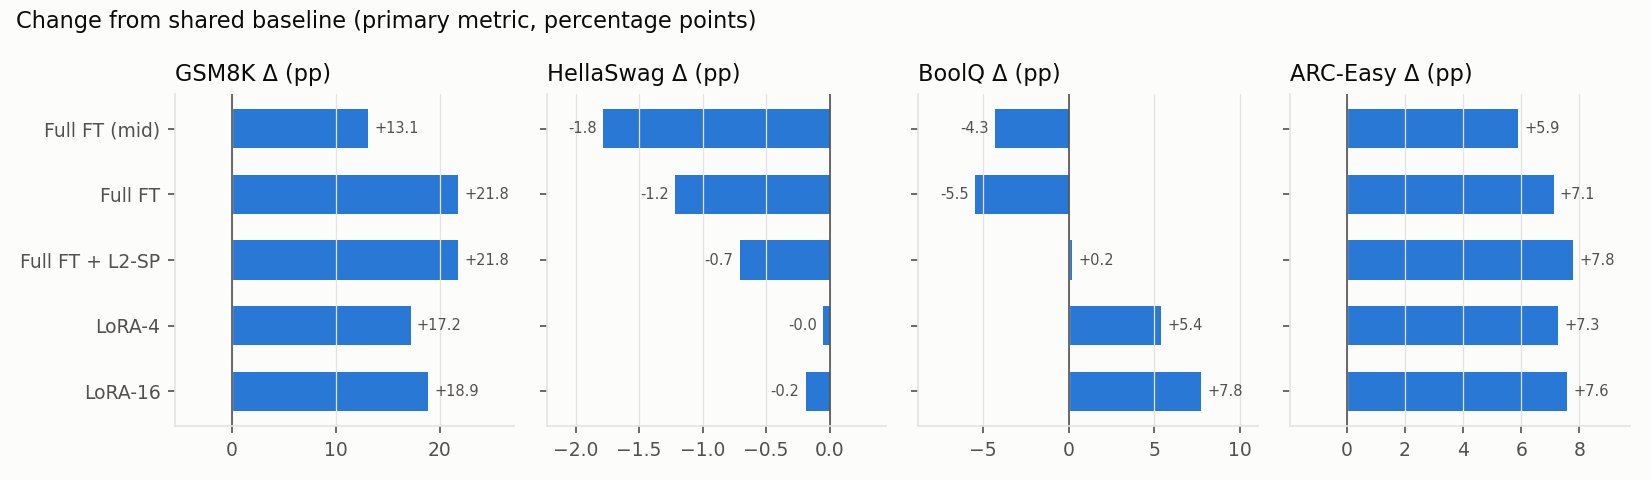

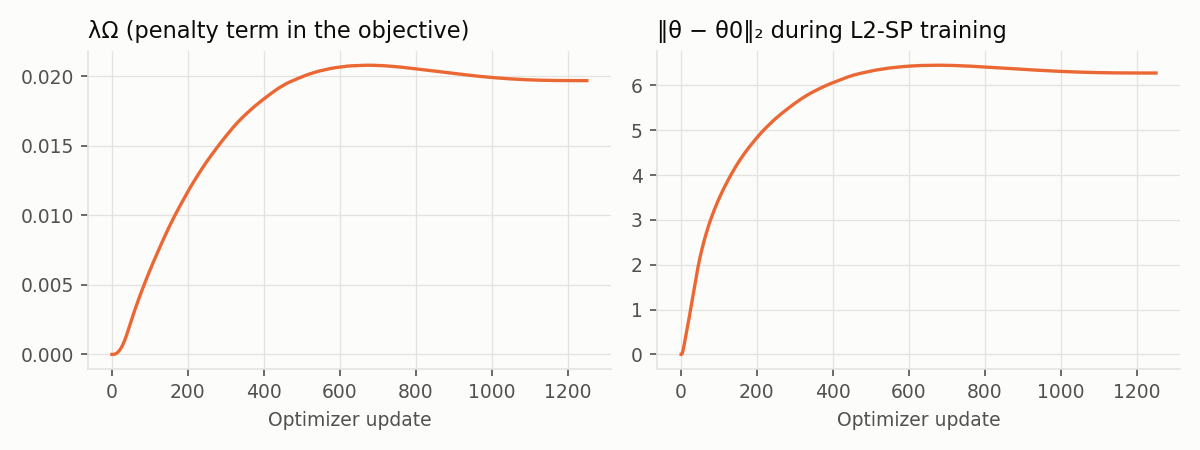

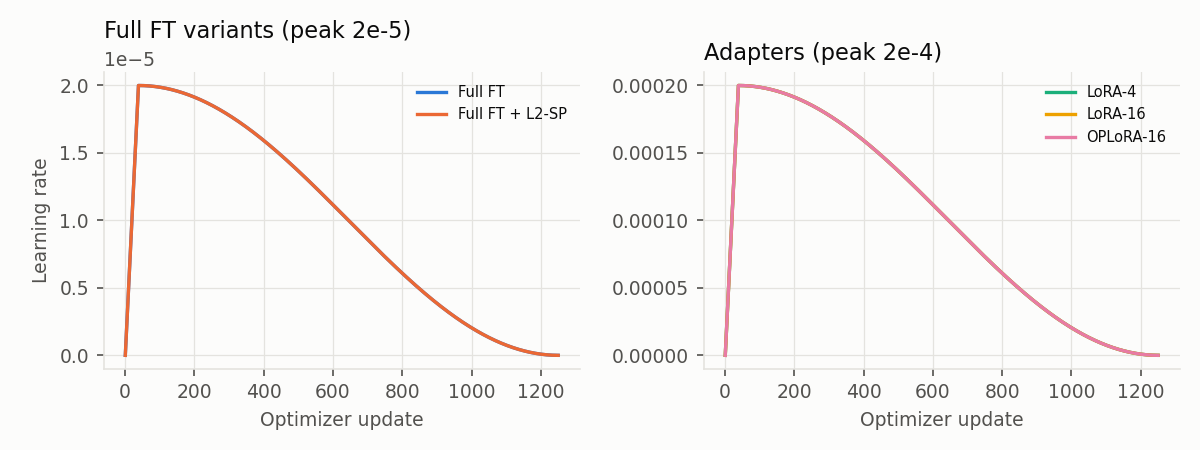

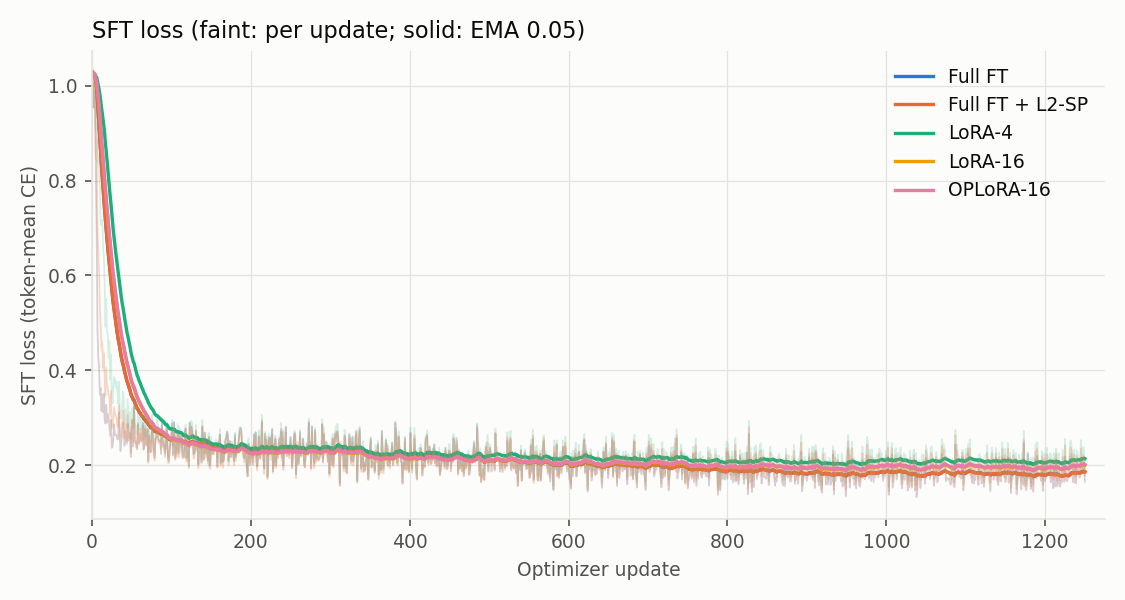

In [5]:
# ============================ RESULTS ============================
import json
from pathlib import Path
from IPython.display import Markdown, Image, display
R = Path(OUTPUT_ROOT)
if (R / "status.json").exists():
    print(json.dumps(json.loads((R / "status.json").read_text()), indent=1))
for t in sorted((R / "report_assets/tables").glob("*.md")) if (R / "report_assets/tables").exists() else []:
    display(Markdown(f"**{t.name}**\n\n" + t.read_text()))
for f in sorted((R / "report_assets/figures").glob("*.png")) if (R / "report_assets/figures").exists() else []:
    display(Image(filename=str(f)))